In [1]:
import os
import sys

cwd = os.path.dirname(os.path.abspath("."))
print(cwd)

sys.path.append(cwd)

import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF
import cv2
import numpy as np
from torch.utils.data import DataLoader


from dataset.st import SceneTextDataset

/home2/ameyk/cv/assignment-3-ameykaran/q1


Dataset size: 91
Image shape  : torch.Size([1, 3, 284, 379])
Bboxes shape : torch.Size([1, 3, 5])
Labels shape : torch.Size([1, 3])


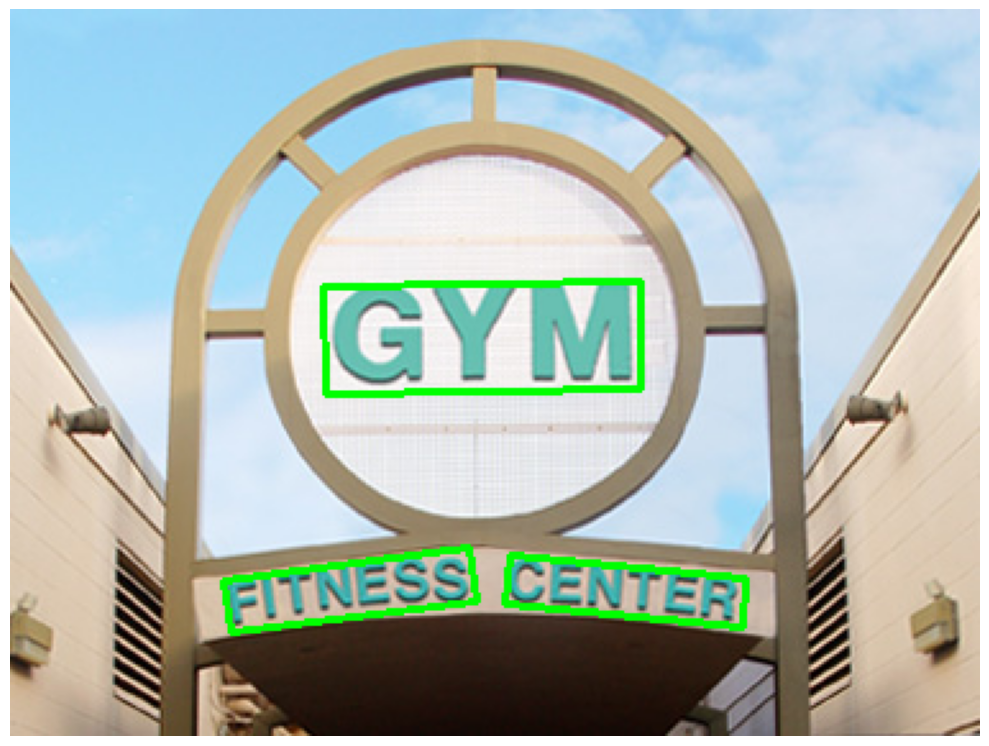

Image shape  : torch.Size([1, 3, 480, 640])
Bboxes shape : torch.Size([1, 3, 5])
Labels shape : torch.Size([1, 3])


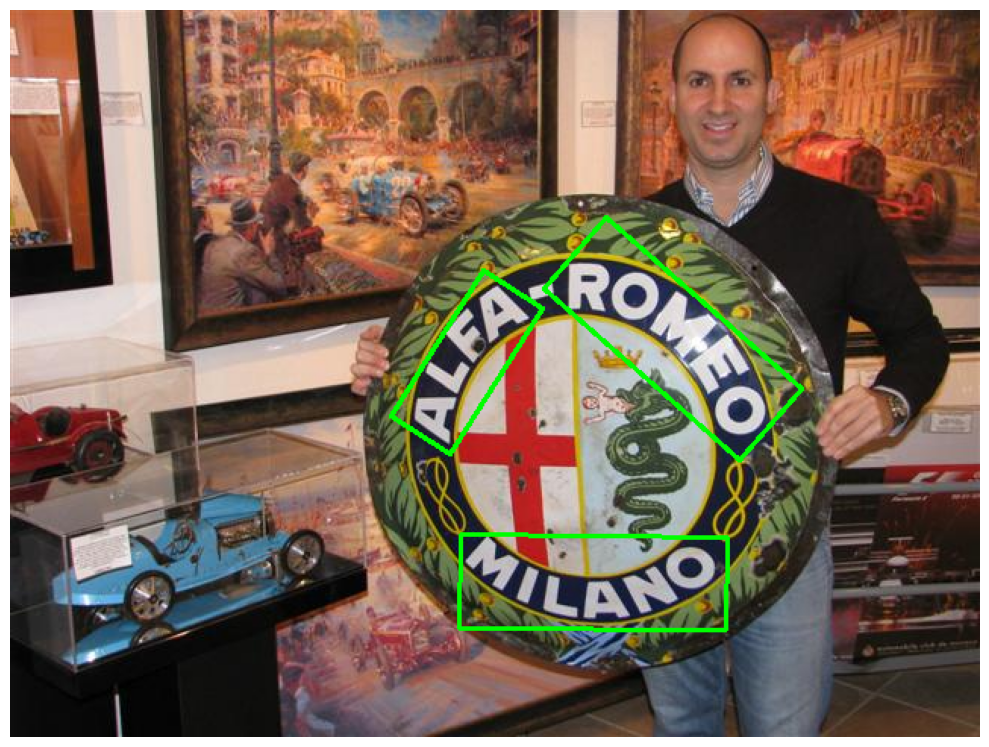

Image shape  : torch.Size([1, 3, 1125, 1687])
Bboxes shape : torch.Size([1, 2, 5])
Labels shape : torch.Size([1, 2])


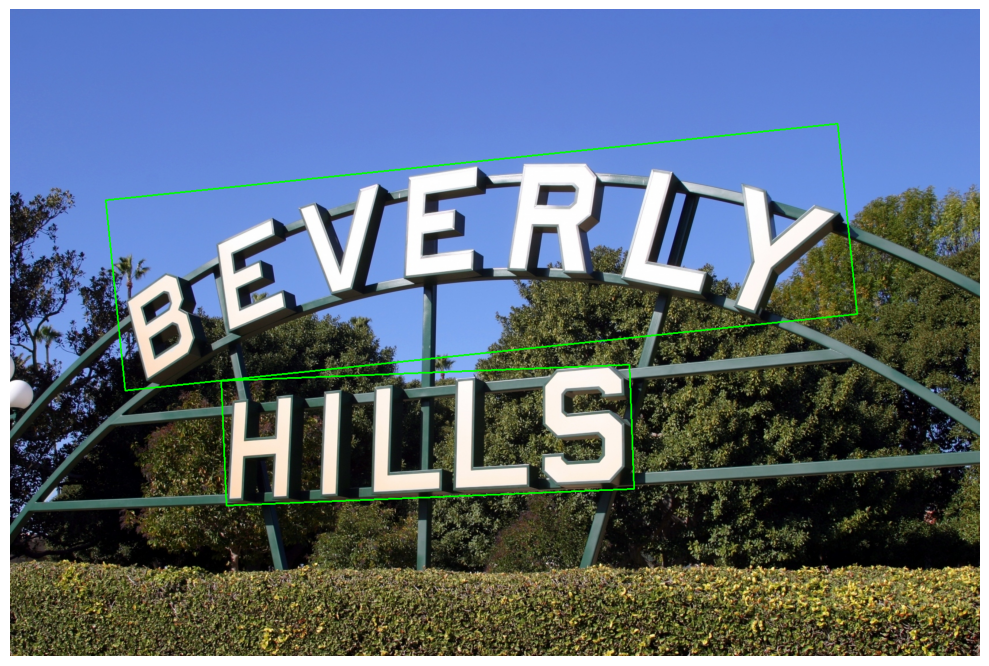

Image shape  : torch.Size([1, 3, 428, 1000])
Bboxes shape : torch.Size([1, 3, 5])
Labels shape : torch.Size([1, 3])


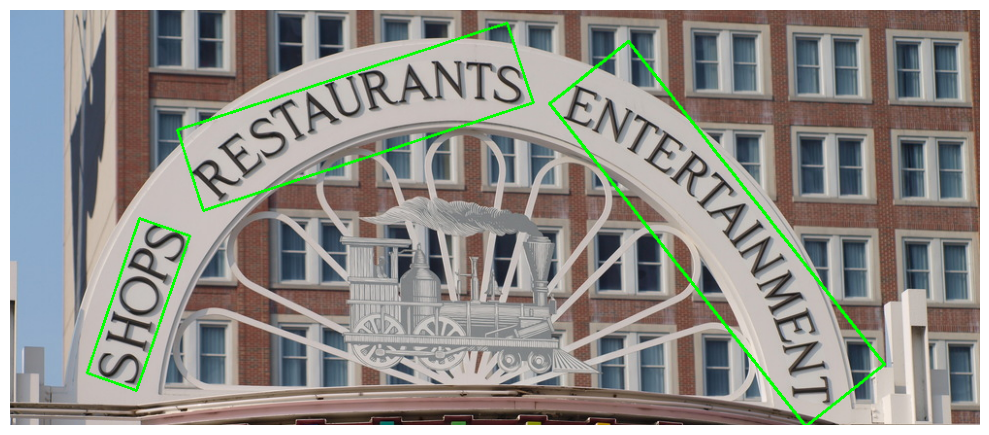

Image shape  : torch.Size([1, 3, 306, 460])
Bboxes shape : torch.Size([1, 5, 5])
Labels shape : torch.Size([1, 5])


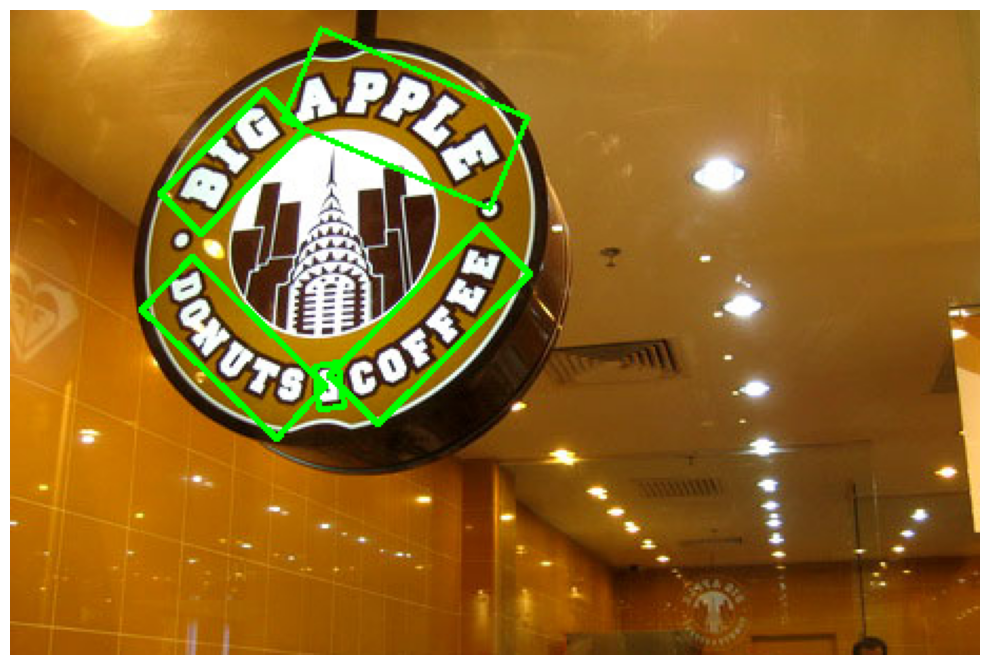

In [2]:
dataset = SceneTextDataset('test', '/home2/ameyk/cv/assignment-3-ameykaran/q1/data')
print(f"Dataset size: {len(dataset)}")

train_loader = DataLoader(dataset, batch_size=1, shuffle=True)

for ind, (im, targets, im_path) in enumerate(train_loader):
    if ind == 5: break
    print("Image shape  :", im.shape)
    print("Bboxes shape :", targets['bboxes'].shape)   # [1, N, 5]
    print("Labels shape :", targets['labels'].shape)

    gt_im = cv2.imread(im_path[0])
    gt_im = cv2.cvtColor(gt_im, cv2.COLOR_BGR2RGB)

    for idx, box in enumerate(targets['bboxes'][0]):
        xc_b, yc_b, w_b, h_b, theta_b = box.tolist()

        # cv2.boxPoints expects ((cx,cy), (w,h), angle_degrees)
        rect = ((xc_b, yc_b), (w_b, h_b), theta_b)
        corners = cv2.boxPoints(rect)                  # (4,2) float32
        corners = np.intp(corners)

        cv2.drawContours(gt_im, [corners], 0, color=[0, 255, 0], thickness=2)

    plt.figure(figsize=(10, 8))
    plt.imshow(gt_im)
    plt.axis('off')
    plt.tight_layout()
    plt.savefig('output_frcnn_gt_obb.png', bbox_inches='tight')
    plt.show()